## improting libraries

In [131]:
## importatant libraries
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import xgboost 
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score,mean_absolute_error


## loading data sets 

In [132]:
data1 = pd.read_csv('kenya_land_registry_parcels_messy.csv')
data1.head()

,record_id,title_number,old_title_number,county,sub_county,ward,nearest_town,registry_office,latitude,longitude,...,disputed,court_case_no,land_ownership_source,digitisation_status,distance_to_tarmac_km,flood_risk,soil_type,rainfall_zone,remarks,suspected_fraud_flag
0,LR0091025,NAIROBI/KARURA/18334,NaN,Nairobi,Kamukunji,Kamukunji North,Nairobi,Nairobi Lands Registry,-1.2873493,36.8190755,...,Y,ELC Petition E381 of 2018,Manual Ledger,Migrated,NaN,Low,Red volcanic,Zone V,NaN,0.0
1,LR0096119,KAKAMEGA/KANYARIRI/94313,KAKAMEGA/WEST/91089,Kakamega,Mumias East,Mumias South,Mumias,Kakamega Lands Registry,0.301589,34.755907,...,N,NaN,Legacy Registry,Partial,NaN,NaN,Sandy loam,Zone V,NaN,0.0
2,LR0083166,TURKANA/WEST/20510,NaN,Turkana,Loima,Loima South,Lodwar,Turkana Lands Registry,3.43985358,35.14880629,...,N,NaN,Ardhisasa,Partial,NaN,Low,Alluvial,Zone III,ukubwa haulingani na deed plan,0.0
3,LR0001529,MAKUENI/WEST/6316,NaN,Makueni,Kibwezi West,Kibwezi South,Emali,Makueni Lands Registry,-1.86408724,37.43876570,...,N,NaN,Settlement Scheme,Migrated,22.72,Low,NaN,Zone V,NaN,0.0
4,LR0085017,IR 65526,NaN,Mombasa,Kisauni,Kisauni Township,Mombasa,Mombasa Lands Registry,-4.0054662,39.6261299,...,N,NaN,Ardhisasa,Migrated,14.55,Medium,Murram,Zone I,Reg. error corrected 04/12/21,0.0


In [133]:
data2 = pd.read_csv('kenya_land_registry_parcels_messy.csv')
data2.head()

,record_id,title_number,old_title_number,county,sub_county,ward,nearest_town,registry_office,latitude,longitude,...,disputed,court_case_no,land_ownership_source,digitisation_status,distance_to_tarmac_km,flood_risk,soil_type,rainfall_zone,remarks,suspected_fraud_flag
0,LR0091025,NAIROBI/KARURA/18334,NaN,Nairobi,Kamukunji,Kamukunji North,Nairobi,Nairobi Lands Registry,-1.2873493,36.8190755,...,Y,ELC Petition E381 of 2018,Manual Ledger,Migrated,NaN,Low,Red volcanic,Zone V,NaN,0.0
1,LR0096119,KAKAMEGA/KANYARIRI/94313,KAKAMEGA/WEST/91089,Kakamega,Mumias East,Mumias South,Mumias,Kakamega Lands Registry,0.301589,34.755907,...,N,NaN,Legacy Registry,Partial,NaN,NaN,Sandy loam,Zone V,NaN,0.0
2,LR0083166,TURKANA/WEST/20510,NaN,Turkana,Loima,Loima South,Lodwar,Turkana Lands Registry,3.43985358,35.14880629,...,N,NaN,Ardhisasa,Partial,NaN,Low,Alluvial,Zone III,ukubwa haulingani na deed plan,0.0
3,LR0001529,MAKUENI/WEST/6316,NaN,Makueni,Kibwezi West,Kibwezi South,Emali,Makueni Lands Registry,-1.86408724,37.43876570,...,N,NaN,Settlement Scheme,Migrated,22.72,Low,NaN,Zone V,NaN,0.0
4,LR0085017,IR 65526,NaN,Mombasa,Kisauni,Kisauni Township,Mombasa,Mombasa Lands Registry,-4.0054662,39.6261299,...,N,NaN,Ardhisasa,Migrated,14.55,Medium,Murram,Zone I,Reg. error corrected 04/12/21,0.0


## merging the data sets s

In [134]:
df=data1.merge(data2, how='inner', on='record_id')
df

,record_id,title_number_x,old_title_number_x,county_x,sub_county_x,ward_x,nearest_town_x,registry_office_x,latitude_x,longitude_x,...,disputed_y,court_case_no_y,land_ownership_source_y,digitisation_status_y,distance_to_tarmac_km_y,flood_risk_y,soil_type_y,rainfall_zone_y,remarks_y,suspected_fraud_flag_y
0,LR0091025,NAIROBI/KARURA/18334,NaN,Nairobi,Kamukunji,Kamukunji North,Nairobi,Nairobi Lands Registry,-1.2873493,36.8190755,...,Y,ELC Petition E381 of 2018,Manual Ledger,Migrated,NaN,Low,Red volcanic,Zone V,NaN,0.0
1,LR0096119,KAKAMEGA/KANYARIRI/94313,KAKAMEGA/WEST/91089,Kakamega,Mumias East,Mumias South,Mumias,Kakamega Lands Registry,0.301589,34.755907,...,N,NaN,Legacy Registry,Partial,NaN,NaN,Sandy loam,Zone V,NaN,0.0
2,LR0083166,TURKANA/WEST/20510,NaN,Turkana,Loima,Loima South,Lodwar,Turkana Lands Registry,3.43985358,35.14880629,...,N,NaN,Ardhisasa,Partial,NaN,Low,Alluvial,Zone III,ukubwa haulingani na deed plan,0.0
3,LR0001529,MAKUENI/WEST/6316,NaN,Makueni,Kibwezi West,Kibwezi South,Emali,Makueni Lands Registry,-1.86408724,37.43876570,...,N,NaN,Settlement Scheme,Migrated,22.72,Low,NaN,Zone V,NaN,0.0
4,LR0085017,IR 65526,NaN,Mombasa,Kisauni,Kisauni Township,Mombasa,Mombasa Lands Registry,-4.0054662,39.6261299,...,N,NaN,Ardhisasa,Migrated,14.55,Medium,Murram,Zone I,Reg. error corrected 04/12/21,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125755,LR0048057,KILIFI/SUB LOC 2/1418,NaN,Kilifi,Kilifi North,Kilifi Central,Mtwapa,Kilifi Lands Registry,-3.464971,39.621469,...,N,NaN,Ardhisasa,Not Migrated,NaN,Medium,Murram,Zone II,NaN,0.0
125756,LR0059012,I.R. 23386,NaN,MURANG'A,Kandara,Kandara East,Murang'a,NaN,307265,9927735,...,N,NaN,Adjudication,Migrated,2.08,Medium,Clay,ASAL,Awaiting survey,0.0
125757,LR0077050,I.R. 60958,NaN,Turkana,Loima,Loima South,Lodwar,Turkana Lands Registry,3.91628,36.74509,...,N,NaN,Ardhisasa,Migrated,10.42,Low,Black cotton,NaN,Awaiting survey,0.0
125758,LR0067225,KAKAMEGA/KIRIAINI/63846,KAKAMEGA/LOWER/41989,Kakamega,Mumias East,NaN,Mumias,Kakamega Lands Registry,0.23658,34.86661,...,N,NaN,Ardhisasa,Migrated,19.31,Low,Red volcanic,Zone II,Ownership in dispute - family,0.0


## data understating 


In [135]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125760 entries, 0 to 125759
Data columns (total 99 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   record_id                125760 non-null  object 
 1   title_number_x           125760 non-null  object 
 2   old_title_number_x       12508 non-null   object 
 3   county_x                 125760 non-null  object 
 4   sub_county_x             125760 non-null  object 
 5   ward_x                   104695 non-null  object 
 6   nearest_town_x           125760 non-null  object 
 7   registry_office_x        100410 non-null  object 
 8   latitude_x               122861 non-null  object 
 9   longitude_x              122861 non-null  object 
 10  coord_system_x           102945 non-null  object 
 11  elevation_m_x            75602 non-null   float64
 12  parcel_size_x            120693 non-null  object 
 13  size_unit_x              120693 non-null  object 
 14  parc

In [136]:
df = df.drop(columns=[c for c in df.columns if c.endswith("_y")])
df.columns = [c[:-2] if c.endswith("_x") else c for c in df.columns]
df.shape   # (125760, 50)

(125760, 50)

In [137]:
df.describe()

,elevation_m,parcel_size_acres_est,num_co_owners,charge_amount_kes,annual_land_rent_kes,rates_arrears_kes,last_txn_amount_kes,txn_count,sales_count,distance_to_tarmac_km,suspected_fraud_flag
count,75602.000000,37687.000000,114244.000000,2.989700e+04,2.814700e+04,1.131280e+05,1.257600e+05,125760.000000,125760.000000,100575.000000,112938.000000
mean,1281.843073,1.977587,1.110063,3.593513e+06,3.619948e+04,2.435039e+04,1.235608e+06,2.760552,0.738240,5.464725,0.050523
std,570.556806,4.828516,0.312969,2.116274e+07,2.471685e+05,2.965561e+05,1.054339e+07,1.915004,1.038972,7.141426,0.219023
min,0.000000,0.020000,1.000000,3.490000e+02,4.000000e+00,0.000000e+00,-1.341102e+08,1.000000,0.000000,0.000000,0.000000
25%,1123.000000,0.064500,1.000000,1.407880e+05,1.479500e+03,0.000000e+00,5.604500e+03,1.000000,0.000000,1.120000,0.000000
50%,1425.000000,0.200500,1.000000,5.250660e+05,5.542000e+03,0.000000e+00,7.878900e+04,2.000000,0.000000,2.910000,0.000000
75%,1657.000000,1.926000,1.000000,1.903155e+06,1.970850e+04,2.685250e+03,4.382540e+05,4.000000,1.000000,6.790000,0.000000
max,2825.000000,147.043600,2.000000,1.213163e+09,1.821977e+07,5.469561e+07,1.138811e+09,13.000000,10.000000,100.920000,1.000000


## checking for data quality  and cleaning 

In [138]:
null_df = df.isnull().sum()/len(df)*100
null_df

record_id                 0.000000
title_number              0.000000
old_title_number         90.054071
county                    0.000000
sub_county                0.000000
ward                     16.750159
nearest_town              0.000000
registry_office          20.157443
latitude                  2.305184
longitude                 2.305184
coord_system             18.141698
elevation_m              39.883906
parcel_size               4.029103
size_unit                 4.029103
parcel_size_acres_est    70.032602
land_use                  2.141380
tenure_type               2.111164
survey_plan_no            0.000000
deed_plan_no             29.934796
registration_date         3.280057
current_owner_name        0.000000
owner_type                6.883747
owner_id_number           4.541985
owner_kra_pin            26.692907
owner_phone              31.154580
owner_email              71.828880
num_co_owners             9.157125
encumbrance_status       50.473919
lender_name         

In [139]:
df=df.drop(columns=[c for c in df.columns if null_df[c]>50])

In [140]:
df.duplicated().sum()

np.int64(3097)

In [141]:
df.drop_duplicates(inplace=True)

In [142]:
df.nunique(dropna=False)

record_id                122160
title_number             119751
county                      144
sub_county                 2020
ward                        513
nearest_town                 42
registry_office              25
latitude                 108195
longitude                106526
coord_system                  9
elevation_m                2440
parcel_size               32625
size_unit                    10
land_use                     17
tenure_type                   9
survey_plan_no            82063
deed_plan_no              56632
registration_date         71468
current_owner_name        64582
owner_type                    7
owner_id_number          112810
owner_kra_pin             87986
owner_phone               82985
num_co_owners                 3
assessed_value_kes       100782
valuation_date            28349
rates_arrears_kes         23579
last_txn_type                16
last_txn_date             68543
last_txn_amount_kes       85857
txn_count                    13
sales_co

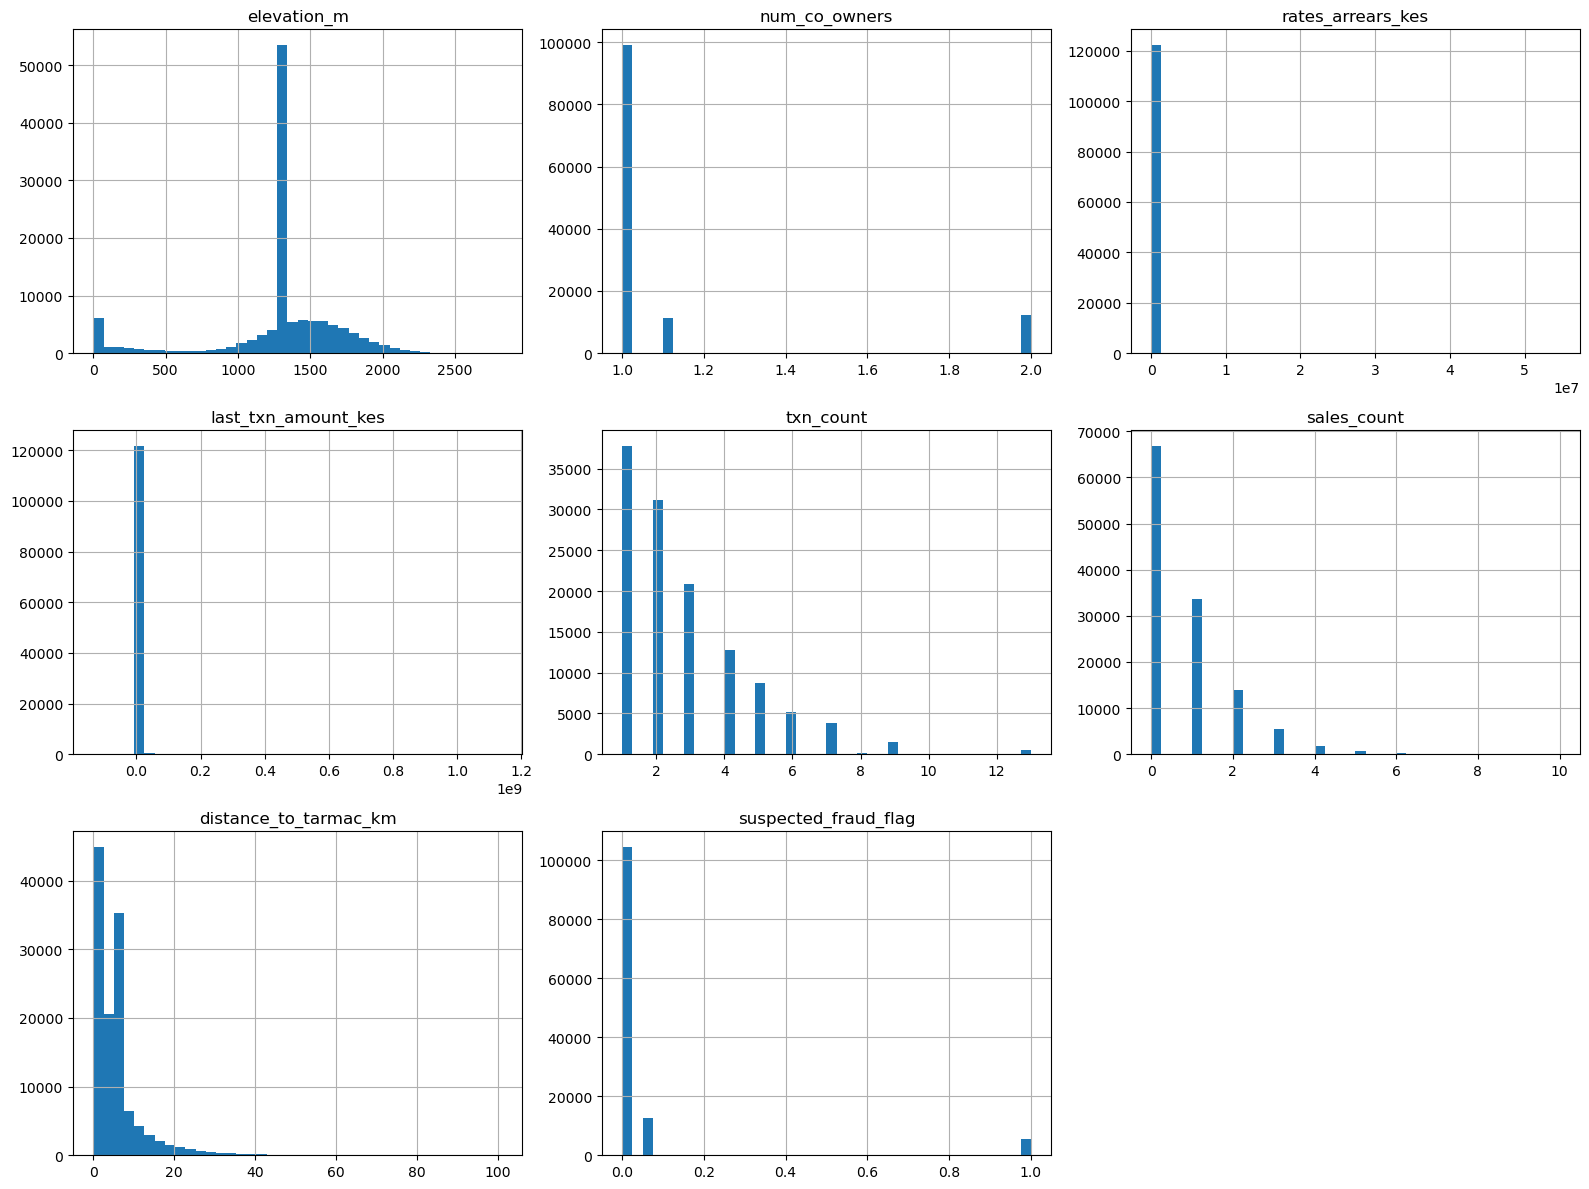

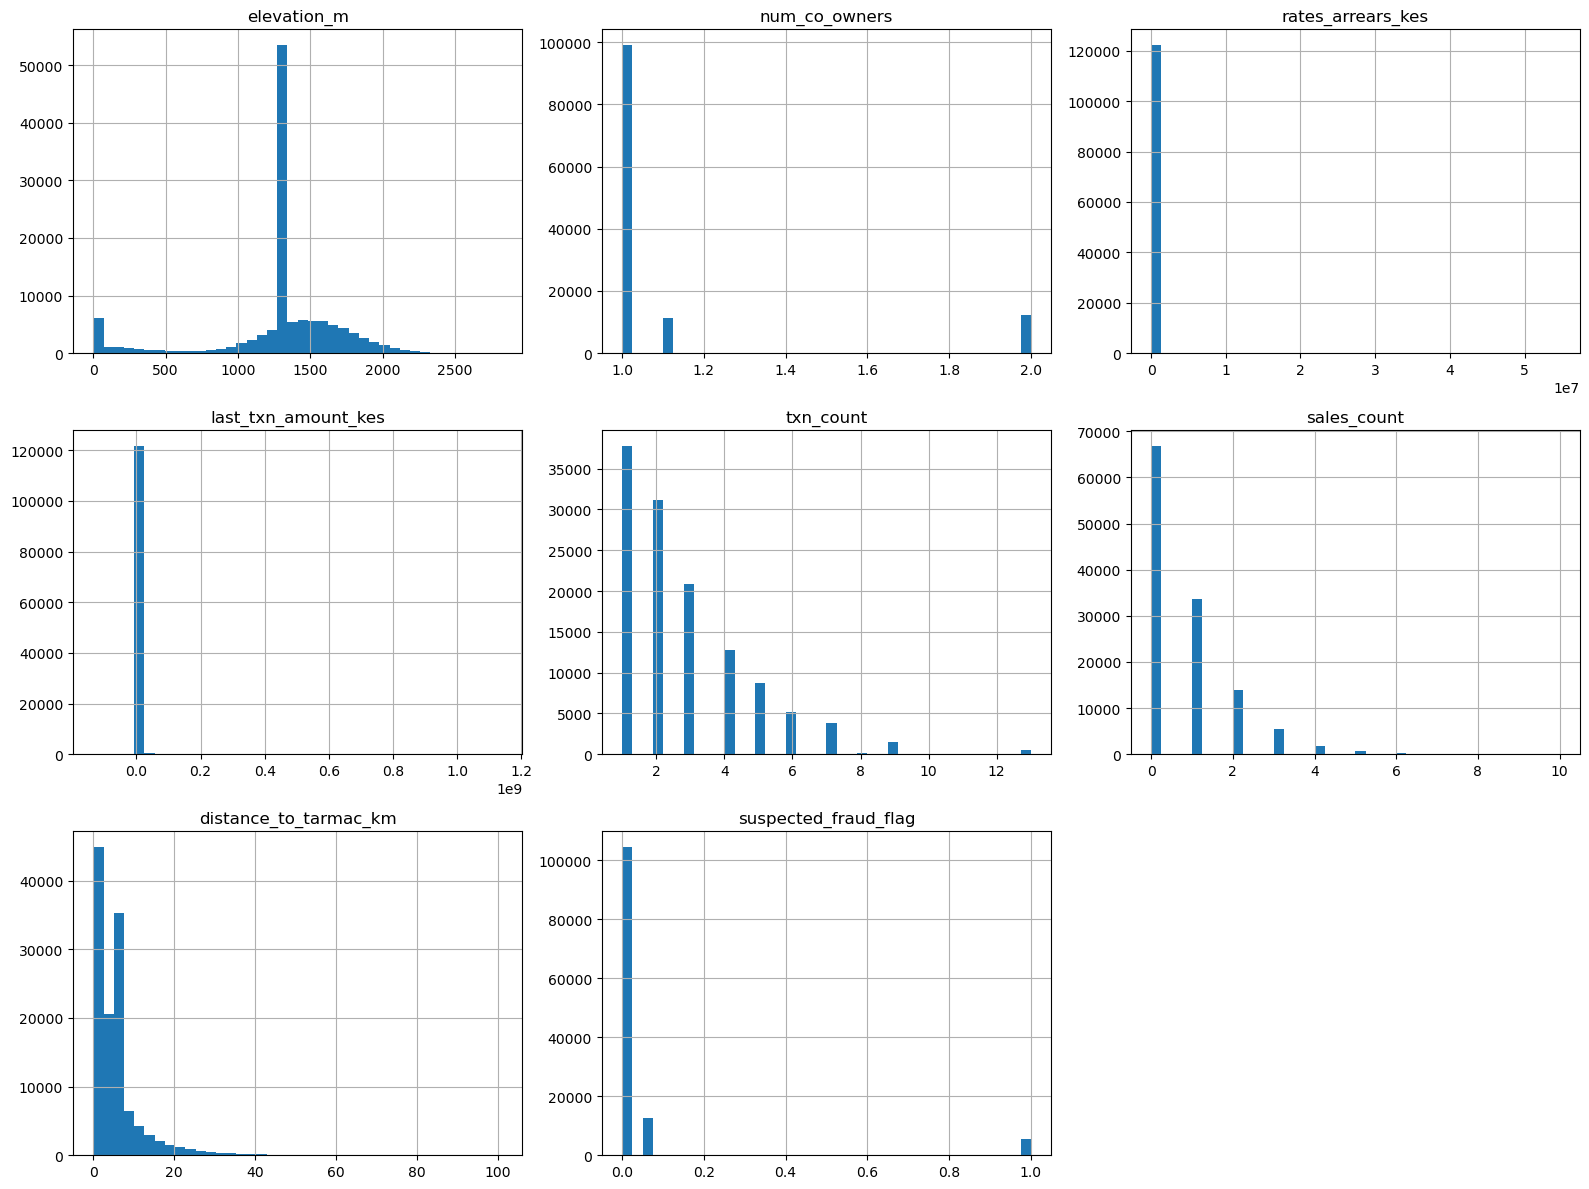

In [143]:
numerical_col = df.select_dtypes(include="number").columns
df[numerical_col] = df[numerical_col].fillna(df[numerical_col].mean())

df[numerical_col].hist(bins=40, figsize=(16, 12))
plt.tight_layout()
plt.show()
df[numerical_col] = df[numerical_col].fillna(df[numerical_col].mean())

df[numerical_col].hist(bins=40, figsize=(16, 12))
plt.tight_layout()
plt.show()



In [144]:
categorical_col=df.select_dtypes(include=['object']).columns
categorical_col 
df[categorical_col] = df[categorical_col].fillna(df[categorical_col].mode().iloc[0])

In [145]:
df.head()

,record_id,title_number,county,sub_county,ward,nearest_town,registry_office,latitude,longitude,coord_system,...,transaction_history,disputed,land_ownership_source,digitisation_status,distance_to_tarmac_km,flood_risk,soil_type,rainfall_zone,remarks,suspected_fraud_flag
0,LR0091025,NAIROBI/KARURA/18334,Nairobi,Kamukunji,Kamukunji North,Nairobi,Nairobi Lands Registry,-1.2873493,36.8190755,WGS84,...,1990-05-05|Adjudication / First Registration|R...,Y,Manual Ledger,Migrated,5.467502,Low,Red volcanic,Zone V,Beacon missing,0.0
1,LR0096119,KAKAMEGA/KANYARIRI/94313,Kakamega,Mumias East,Mumias South,Mumias,Kakamega Lands Registry,0.301589,34.755907,WGS84,...,1997-08-07|Adjudication / First Registration|N...,N,Legacy Registry,Partial,5.467502,Low,Sandy loam,Zone V,Beacon missing,0.0
2,LR0083166,TURKANA/WEST/20510,Turkana,Loima,Loima South,Lodwar,Turkana Lands Registry,3.43985358,35.14880629,EPSG:4326,...,1990-05-05|Adjudication / First Registration|R...,N,Ardhisasa,Partial,5.467502,Low,Alluvial,Zone III,ukubwa haulingani na deed plan,0.0
3,LR0001529,MAKUENI/WEST/6316,Makueni,Kibwezi West,Kibwezi South,Emali,Makueni Lands Registry,-1.86408724,37.43876570,Arc 1960,...,1980-02-28|Adjudication / First Registration|K...,N,Settlement Scheme,Migrated,22.720000,Low,Sandy loam,Zone V,Beacon missing,0.0
4,LR0085017,IR 65526,Mombasa,Kisauni,Kisauni Township,Mombasa,Mombasa Lands Registry,-4.0054662,39.6261299,Arc 1960,...,1984-10-28|Adjudication / First Registration|H...,N,Ardhisasa,Migrated,14.550000,Medium,Murram,Zone I,Reg. error corrected 04/12/21,0.0


In [146]:
df.columns

Index(['record_id', 'title_number', 'county', 'sub_county', 'ward',
       'nearest_town', 'registry_office', 'latitude', 'longitude',
       'coord_system', 'elevation_m', 'parcel_size', 'size_unit', 'land_use',
       'tenure_type', 'survey_plan_no', 'deed_plan_no', 'registration_date',
       'current_owner_name', 'owner_type', 'owner_id_number', 'owner_kra_pin',
       'owner_phone', 'num_co_owners', 'assessed_value_kes', 'valuation_date',
       'rates_arrears_kes', 'last_txn_type', 'last_txn_date',
       'last_txn_amount_kes', 'txn_count', 'sales_count',
       'transaction_history', 'disputed', 'land_ownership_source',
       'digitisation_status', 'distance_to_tarmac_km', 'flood_risk',
       'soil_type', 'rainfall_zone', 'remarks', 'suspected_fraud_flag'],
      dtype='object')

In [148]:
s = df["disputed"].astype(str).str.strip().str.lower()
print(s.value_counts())    # see every variant before mapping

mapping = {"yes": 1, "y": 1, "true": 1, "1": 1,
           "no": 0, "n": 0, "false": 0, "0": 0}
df["disputed"] = s.reindex(df.index).map(mapping)

disputed
n                      105528
y                        7351
no                       4897
under investigation      2446
yes                      2441
Name: count, dtype: int64


## visualization

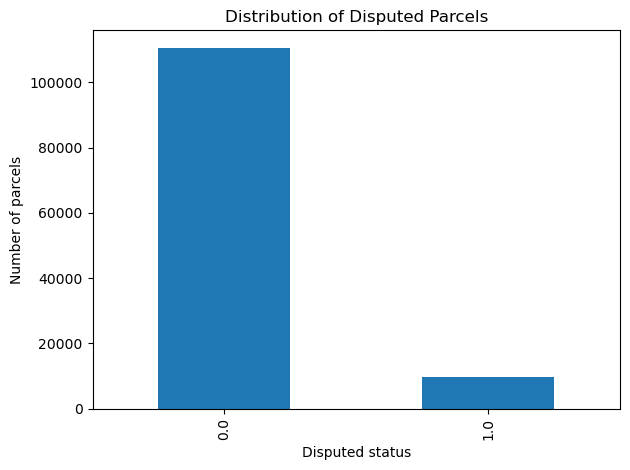

In [153]:
df["disputed"].dropna().value_counts().plot(kind="bar")
plt.title("Distribution of Disputed Parcels")
plt.xlabel("Disputed status")
plt.ylabel("Number of parcels")
plt.tight_layout()
plt.show()

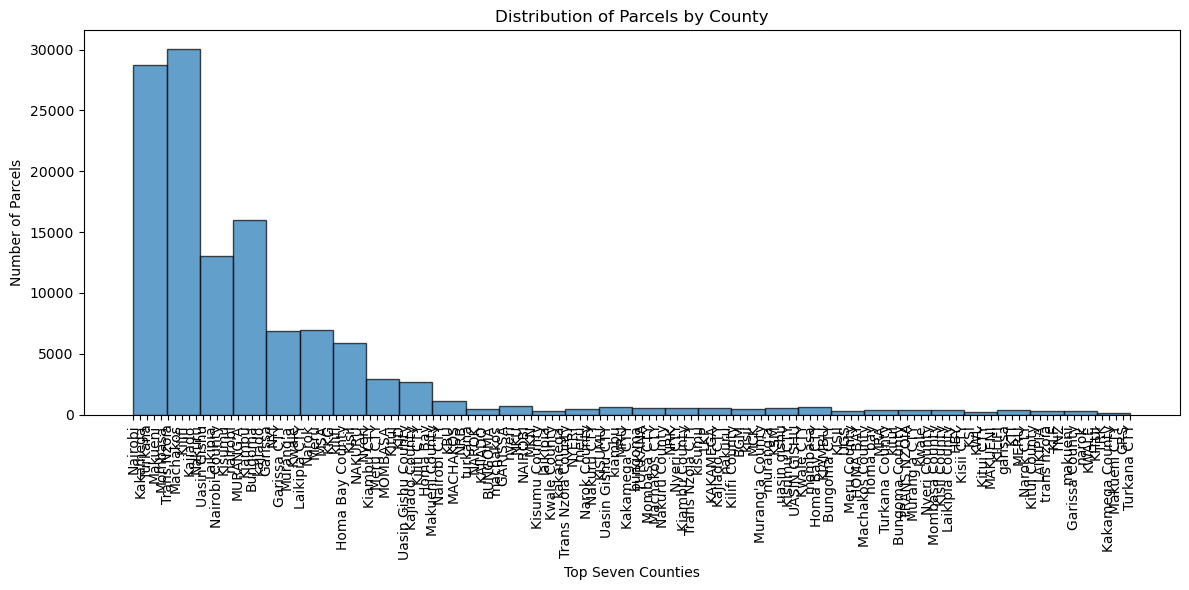

In [155]:
plt.figure(figsize=(12, 6))
plt.hist(df['county'], bins=30, edgecolor='k', alpha=0.7)
plt.title('Distribution of Parcels by County')
plt.xlabel('Top Seven Counties')
plt.ylabel('Number of Parcels')
plt.xticks(rotation=90) 
plt.tight_layout()
plt.show()

In [ ]:
import re

gov_kw = [
    r'government', r'govt', r'\bgok\b', r'county', r'ministry', r'commissioner',
    r'national land commission', r'\bnlc\b', r'municipal', r'city council',
    r'kenya railways', r'kenya power', r'\bkplc\b', r'kenya ports', r'\bkenha\b',
    r'\bkura\b', r'\bkerra\b', r'parastatal', r'state corporation', r'republic of kenya',
]
company_kw = [
    r'\bltd\b', r'limited', r'\binc\b', r'\bplc\b', r'\bllc\b', r'company',
    r'\bco\b', r'holdings', r'investments?', r'enterprises?', r'properties',
    r'developers?', r'\bbank\b', r'insurance', r'ventures', r'group', r'agencies',
    r'real estate', r'construction',
]
other_kw = [
    r'sacco', r'co-?operative', r'society', r'trust', r'trustees', r'church',
    r'mosque', r'temple', r'diocese', r'ministries', r'school', r'college',
    r'university', r'hospital', r'foundation', r'ngo', r'association',
    r'welfare', r'self help', r'women group', r'youth group', r'estate of',
    r'deceased', r'\bestate\b', r'registered trustees', r'club',
]

def has_match(text, patterns):
    return any(re.search(p, text) for p in patterns)

def classify_owner(text):
    if text in ('', 'nan', 'unknown', 'none'):
        return 'Unknown'
    if has_match(text, gov_kw):
        return 'Government'
    if has_match(text, other_kw):      # before company so "Trust Ltd" style cases are reviewed
        return 'Other'
    if has_match(text, company_kw):
        return 'Company'
    return 'Individual'

df['owner_type'] = (
    df['current_owner_name']
    .fillna('')
    .astype(str)
    .str.strip()
    .str.lower()
    .apply(classify_owner)
)
print(df['owner_type'].value_counts())

KeyError: 'owner_clean'